# Question 1A

In [1]:
import pandas as pd 
import numpy as py 
import mariadb

server_address = "localhost"
server_port = 3307
user = "root"
password = "Joelle270403!"

In [2]:
try:
    print("Connecting...")
    connection = mariadb.connect(
        host = server_address,
        port = server_port, 
        username = user,
        password = password
    )
    print("Connected sucessfully!")

except Exception as ex:
    print(f"An error occurred, details are {ex}")

Connecting...
Connected sucessfully!


In [3]:
dbName = "CarbonEmission"
table = "combined"

cursor = None

try:
    cursor = connection.cursor()
    print("Creating database...")
    print("Creating table...")
    query = f"CREATE DATABASE IF NOT EXISTS {dbName};"
    query1 = f"CREATE DATABASE IF NOT EXISTS {table};"
    cursor.execute(query)
    cursor.execute(query1)
    print("Database created!")
    print("Table created!")
    query2 = f"USE {dbName};"
    cursor.execute(query2)
    print(f"Using database {dbName}")
    
    cursor.close()

except Exception as ex:
    print(f"An error occurred, details are {ex}")

Creating database...
Creating table...
Database created!
Table created!
Using database CarbonEmission


In [4]:
def extract(filepath):
    df = pd.read_csv("Q1_logistics_carbon_emissions.csv")
    df.columns = df.columns.str.replace('-', '_')
    df['Route_Type'] = df['Route_Type'].str.replace('-', '_').str.replace(' ', '_')

    print("Columns:", df.columns.tolist())
    print("Route Types:", df['Route_Type'].unique())

    col_definitions = []
    for col, dtype in zip(df.columns, df.dtypes):
        if dtype == 'float64':
            sql_type = 'FLOAT'
        elif dtype == 'int64':
            sql_type = 'INT'
        else:
            sql_type = 'VARCHAR(255)'
        col_definitions.append(f"`{col}` {sql_type}")

    cursor = None
    
    cursor = connection.cursor()
    cursor.execute(f"USE `{dbName}`")
    cursor.execute(f"DROP TABLE IF EXISTS `{table}`")
    cursor.execute(f"CREATE TABLE `{table}` ({', '.join(col_definitions)})")
    
    placeholders = ', '.join(['%s'] * len(df.columns))
    query3 = f"INSERT INTO `{table}` VALUES ({placeholders})"
    cursor.executemany(query3, df.values.tolist())
    connection.commit()
    cursor.close()

    print(f"Extract complete — {len(df)} rows loaded into '{table}'.")
        
    return df

df = extract("Q1_logistics_carbon_emissions.csv")

Columns: ['Transaction_ID', 'Date', 'Origin_Facility', 'Destination_City', 'Vehicle_Type', 'Route_Type', 'Distance_KM', 'Package_Weight_KG', 'Traffic_Conditions', 'Carbon_Emission_kgCO2e', 'Is_Eco_Friendly']
Route Types: <StringArray>
['Mixed_Route', 'Urban_Last_Mile', 'Inter_City', 'Inter_District']
Length: 4, dtype: str
Extract complete — 12000 rows loaded into 'combined'.


In [5]:
def transform(df):
    base_factors = {
        'Bicycle': 0,
        'Drone': 0.02,
        'Electric Van': 0.05,
        'Motorcycle': 0.1,
        'Diesel Van (Euro 6)': 0.2,
        'Diesel Van (Euro 4)': 0.4,
        'Heavy Truck': 1.2
    }
    traffic_multipliers = {
        'Normal': 1,
        'Low traffic': 1.1,
        'High traffic': 1.5,
        'Severe Congestion': 1.75
    }

    def reclassify_route(row):
        if row['Route_Type'] == 'Mixed_Route':
            if row['Distance_KM'] > 100:
                return 'Inter_City'
            elif 20 <= row['Distance_KM'] <= 100:
                return 'Inter_District'
            else:
                return 'Urban_Last_Mile'
        return row['Route_Type']

    df['Route_Type'] = df.apply(reclassify_route, axis=1)
    print("Remaining Mixed_Route:", (df['Route_Type'] == 'Mixed_Route').sum())
    print("Route Type counts:\n", df['Route_Type'].value_counts())

    def calculate_emission(row):
        base     = base_factors.get(row['Vehicle_Type'], 0)
        traffic  = traffic_multipliers.get(row['Traffic_Conditions'], 1)
        load     = row['Package_Weight_KG']
        distance = row['Distance_KM']
        return round(base * load * traffic * distance, 4)

    df['Carbon_Emission_kgCO2e'] = df.apply(calculate_emission, axis=1)
    print("Emission recalculation done.")

    
    cursor = connection.cursor()
    cursor.execute(f"USE `{dbName}`")
    cursor.execute(f"TRUNCATE TABLE `{table}`")
    placeholders = ', '.join(['%s'] * len(df.columns))
    query5 = f"INSERT INTO `{table}` VALUES ({placeholders})"
    cursor.executemany(query5, df.values.tolist())
    connection.commit()
    cursor.close()
    print(f"'{table}' updated with transformed data.")

    return df

df = transform(df)

Remaining Mixed_Route: 0
Route Type counts:
 Route_Type
Inter_District     4709
Urban_Last_Mile    3753
Inter_City         3538
Name: count, dtype: int64
Emission recalculation done.
'combined' updated with transformed data.


In [6]:
def load(df):
    route_tables = {
        'Inter_City':      'Inter_City',
        'Inter_District':  'Inter_District',
        'Urban_Last_Mile': 'Urban_Last_Mile'
    }

    col_definitions = []
    for col, dtype in zip(df.columns, df.dtypes):
        if dtype == 'float64':
            sql_type = 'FLOAT'
        elif dtype == 'int64':
            sql_type = 'INT'
        else:
            sql_type = 'VARCHAR(255)'
        col_definitions.append(f"`{col}` {sql_type}")

    for route_type, table_name in route_tables.items():
        subset = df[df['Route_Type'] == route_type].sort_values('Vehicle_Type')

        cursor = None 
        
        cursor = connection.cursor()
        cursor.execute(f"USE `{dbName}`")
        cursor.execute(f"DROP TABLE IF EXISTS `{table_name}`")
        cursor.execute(f"CREATE TABLE `{table_name}` ({', '.join(col_definitions)})")
        placeholders = ', '.join(['%s'] * len(subset.columns))
        query5 = f"INSERT INTO `{table_name}` VALUES ({placeholders})"
        cursor.executemany(query5, subset.values.tolist())
        connection.commit()
        cursor.close()
        print(f"Table '{table_name}' created — {len(subset)} rows.")
        

    print("Load complete.")

load(df)

Table 'Inter_City' created — 3538 rows.
Table 'Inter_District' created — 4709 rows.
Table 'Urban_Last_Mile' created — 3753 rows.
Load complete.


# Question 1B

In [7]:
cursor = connection.cursor()
cursor.execute(f"USE `{dbName}`")
cursor.execute("SELECT * FROM `combined`")
rows = cursor.fetchall()
cols = [desc[0] for desc in cursor.description]
df_combined = pd.DataFrame(rows, columns=cols)
cursor.close()

# Make sure Date is parsed as datetime and extract Month
df_combined['Date'] = pd.to_datetime(df_combined['Date'])
df_combined['Month'] = df_combined['Date'].dt.month_name()
df_combined['Month_Num'] = df_combined['Date'].dt.month

print(df_combined.shape)
print(df_combined.dtypes)
print(df_combined.head(3))

(12000, 13)
Transaction_ID                       str
Date                      datetime64[us]
Origin_Facility                      str
Destination_City                     str
Vehicle_Type                         str
Route_Type                           str
Distance_KM                      float64
Package_Weight_KG                float64
Traffic_Conditions                   str
Carbon_Emission_kgCO2e           float64
Is_Eco_Friendly                    int64
Month                                str
Month_Num                          int32
dtype: object
  Transaction_ID       Date             Origin_Facility   Destination_City  \
0   TRX-F775953B 2025-02-18  Jakarta Fulfillment Center         Waynehaven   
1   TRX-B4C50003 2025-09-11  Jakarta Fulfillment Center  East Patriciaside   
2   TRX-F7C71F39 2025-06-15              Semarang Depot        Pottershire   

          Vehicle_Type       Route_Type  Distance_KM  Package_Weight_KG  \
0    Electric Van (EV)   Inter_District         80.4 

In [8]:
em_per_route = df_combined.groupby(['Route_Type', 'Vehicle_Type'])['Carbon_Emission_kgCO2e'].sum().reset_index()
em_per_route.columns = ['Route_Type', 'Vehicle_Type', 'Total_Emissions']
em_per_route = em_per_route.sort_values(['Route_Type', 'Total_Emissions'], ascending=[True, False])
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("=== Inference and Insights: Total Emissions per Vehicle Type per Route ===")
print(em_per_route.to_string(index=False))

=== Inference and Insights: Total Emissions per Vehicle Type per Route ===
     Route_Type         Vehicle_Type  Total_Emissions
     Inter_City          Heavy Truck 2,661,288,838.40
     Inter_City  Diesel Van (Euro 4)       538,852.91
     Inter_City  Diesel Van (Euro 6)       247,249.62
     Inter_City    Electric Van (EV)             0.00
 Inter_District  Diesel Van (Euro 4)       399,025.81
 Inter_District  Diesel Van (Euro 6)       190,910.90
 Inter_District    Electric Van (EV)             0.00
 Inter_District Motorcycle (Courier)             0.00
Urban_Last_Mile  Diesel Van (Euro 4)        11,353.69
Urban_Last_Mile  Diesel Van (Euro 6)         6,628.29
Urban_Last_Mile        Cargo Bicycle             0.00
Urban_Last_Mile       Drone Delivery             0.00
Urban_Last_Mile    Electric Van (EV)             0.00


In [9]:
dist_per_route = df_combined.groupby('Route_Type')['Distance_KM'].sum().reset_index()
dist_per_route.columns = ['Route_Type', 'Total_Distance_KM']
dist_per_route = dist_per_route.sort_values('Total_Distance_KM', ascending=False)

print("=== Inference and Insights: Routes Ranked by Total Distance (Descending) ===")
print(dist_per_route.to_string(index=False))

=== Inference and Insights: Routes Ranked by Total Distance (Descending) ===
     Route_Type  Total_Distance_KM
     Inter_City         984,136.70
 Inter_District         217,828.80
Urban_Last_Mile          32,251.40


In [10]:
eco_dist = df_combined.groupby('Is_Eco_Friendly')['Distance_KM'].sum().reset_index()
eco_dist['Is_Eco_Friendly'] = eco_dist['Is_Eco_Friendly'].map({1: 'Eco-Friendly', 0: 'Non-Eco-Friendly'})
eco_dist.columns = ['Category', 'Total_Distance_KM']

print("=== Inference and Insights: Eco-Friendly vs Non-Eco-Friendly Distance ===")
print(eco_dist.to_string(index=False))

=== Inference and Insights: Eco-Friendly vs Non-Eco-Friendly Distance ===
        Category  Total_Distance_KM
Non-Eco-Friendly       1,069,715.40
    Eco-Friendly         164,501.50


In [11]:
em_per_month = df_combined.groupby(['Month_Num', 'Month', 'Vehicle_Type'])['Carbon_Emission_kgCO2e'].sum().reset_index()
em_per_month.columns = ['Month_Num', 'Month', 'Vehicle_Type', 'Total_Emissions']
em_per_month = em_per_month.sort_values(['Month_Num', 'Vehicle_Type'])

print("=== Inference and Insights: Total Emissions per Vehicle Type per Month ===")
print(em_per_month.to_string(index=False))

=== Inference and Insights: Total Emissions per Vehicle Type per Month ===
 Month_Num     Month         Vehicle_Type  Total_Emissions
         1   January        Cargo Bicycle             0.00
         1   January  Diesel Van (Euro 4)        87,892.79
         1   January  Diesel Van (Euro 6)        40,596.60
         1   January       Drone Delivery             0.00
         1   January    Electric Van (EV)             0.00
         1   January          Heavy Truck   264,451,096.00
         1   January Motorcycle (Courier)             0.00
         2  February        Cargo Bicycle             0.00
         2  February  Diesel Van (Euro 4)        79,574.54
         2  February  Diesel Van (Euro 6)        35,429.58
         2  February       Drone Delivery             0.00
         2  February    Electric Van (EV)             0.00
         2  February          Heavy Truck   216,975,948.10
         2  February Motorcycle (Courier)             0.00
         3     March        Cargo Bicycl

In [12]:
connection.close()
print("Done.")

Done.


# Question 1C

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

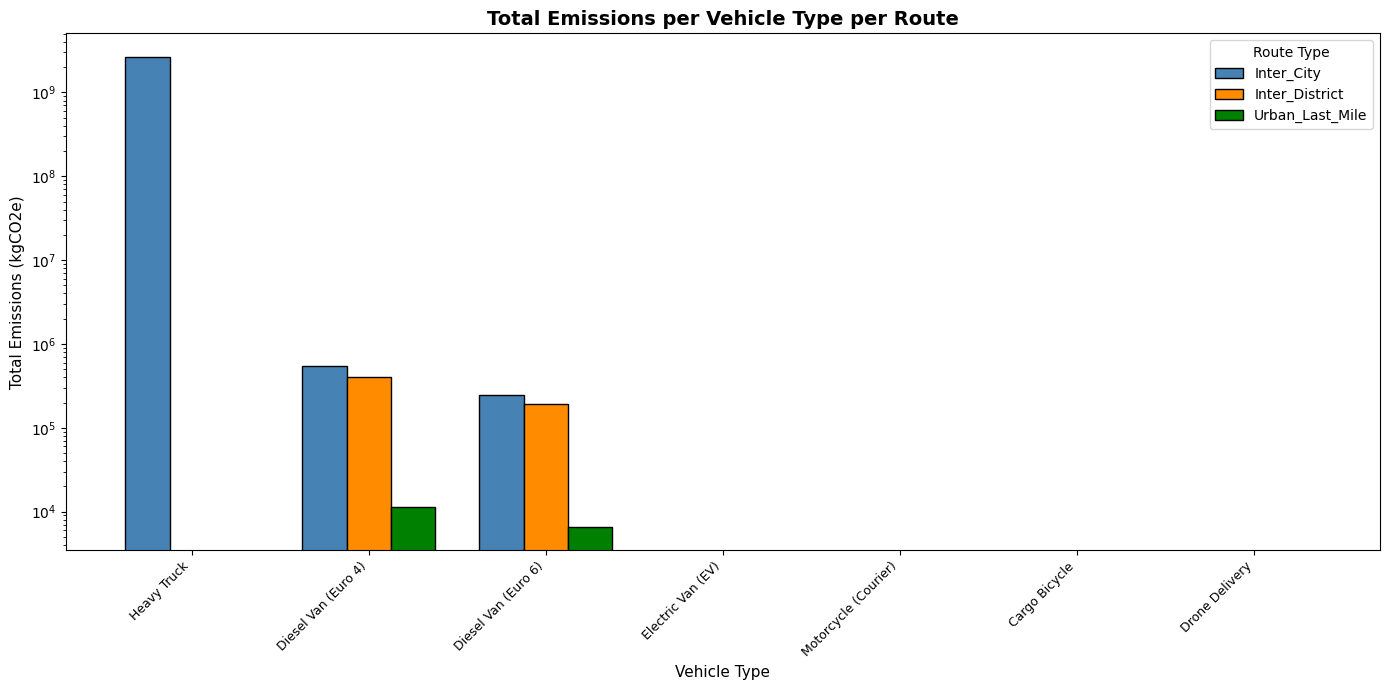

Saved: Visualization_1_emissions_histogram.png


In [14]:
routes = em_per_route['Route_Type'].unique()
vehicle_types = em_per_route['Vehicle_Type'].unique()

route_colors = {
    'Inter_City':      'steelblue',
    'Inter_District':  'darkorange',
    'Urban_Last_Mile': 'green'
}

x = np.arange(len(vehicle_types))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))

for i, route in enumerate(routes):
    data = em_per_route[em_per_route['Route_Type'] == route].set_index('Vehicle_Type')
    values = [data.loc[vt, 'Total_Emissions'] if vt in data.index else 0 for vt in vehicle_types]
    ax.bar(x + i * bar_width, values,
           width=bar_width,
           label=route,
           color=route_colors.get(route, 'grey'),
           edgecolor='black')

ax.set_yscale('log')
ax.set_title('Total Emissions per Vehicle Type per Route', fontsize=14, fontweight='bold')
ax.set_xlabel('Vehicle Type', fontsize=11)
ax.set_ylabel('Total Emissions (kgCO2e)', fontsize=11)
ax.set_xticks(x + bar_width)
ax.set_xticklabels(vehicle_types, rotation=45, ha='right', fontsize=9)
ax.legend(title='Route Type', fontsize=10)

plt.tight_layout()
plt.savefig('Visualization_1_emissions_histogram.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: Visualization_1_emissions_histogram.png")

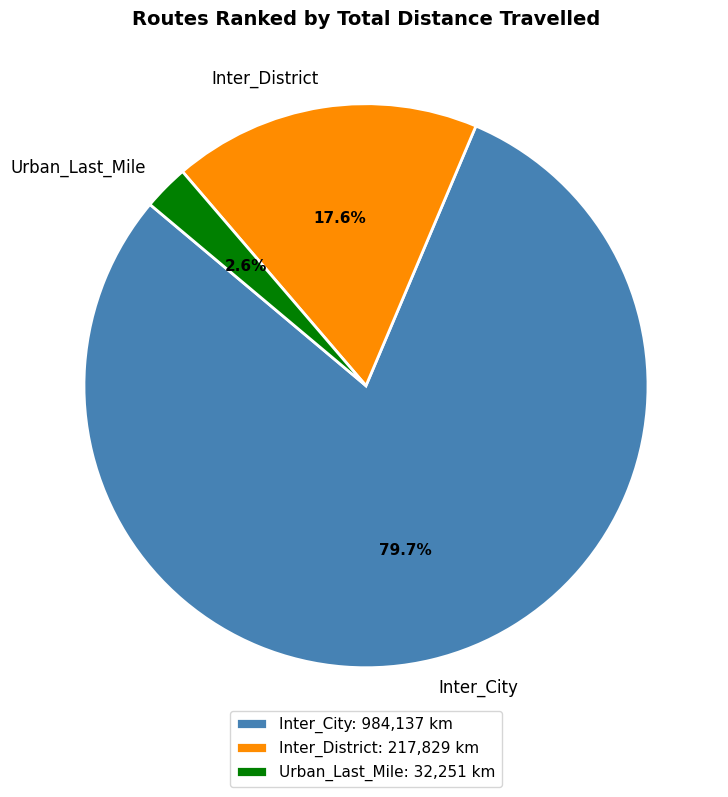

Saved: Visualizations_2_distance_per_route.png


In [15]:
fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    dist_per_route['Total_Distance_KM'],
    labels=dist_per_route['Route_Type'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['steelblue', 'darkorange', 'green'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

for text in texts:
    text.set_fontsize(12)
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')

ax.set_title('Routes Ranked by Total Distance Travelled', fontsize=14, fontweight='bold')

# Add actual km values in legend
legend_labels = [
    f"{row['Route_Type']}: {row['Total_Distance_KM']:,.0f} km"
    for _, row in dist_per_route.iterrows()
]
ax.legend(wedges, legend_labels, loc='lower center', bbox_to_anchor=(0.5, -0.08), fontsize=11)

plt.tight_layout()
plt.savefig('Visualization_2_distance_per_route.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: Visualizations_2_distance_per_route.png")

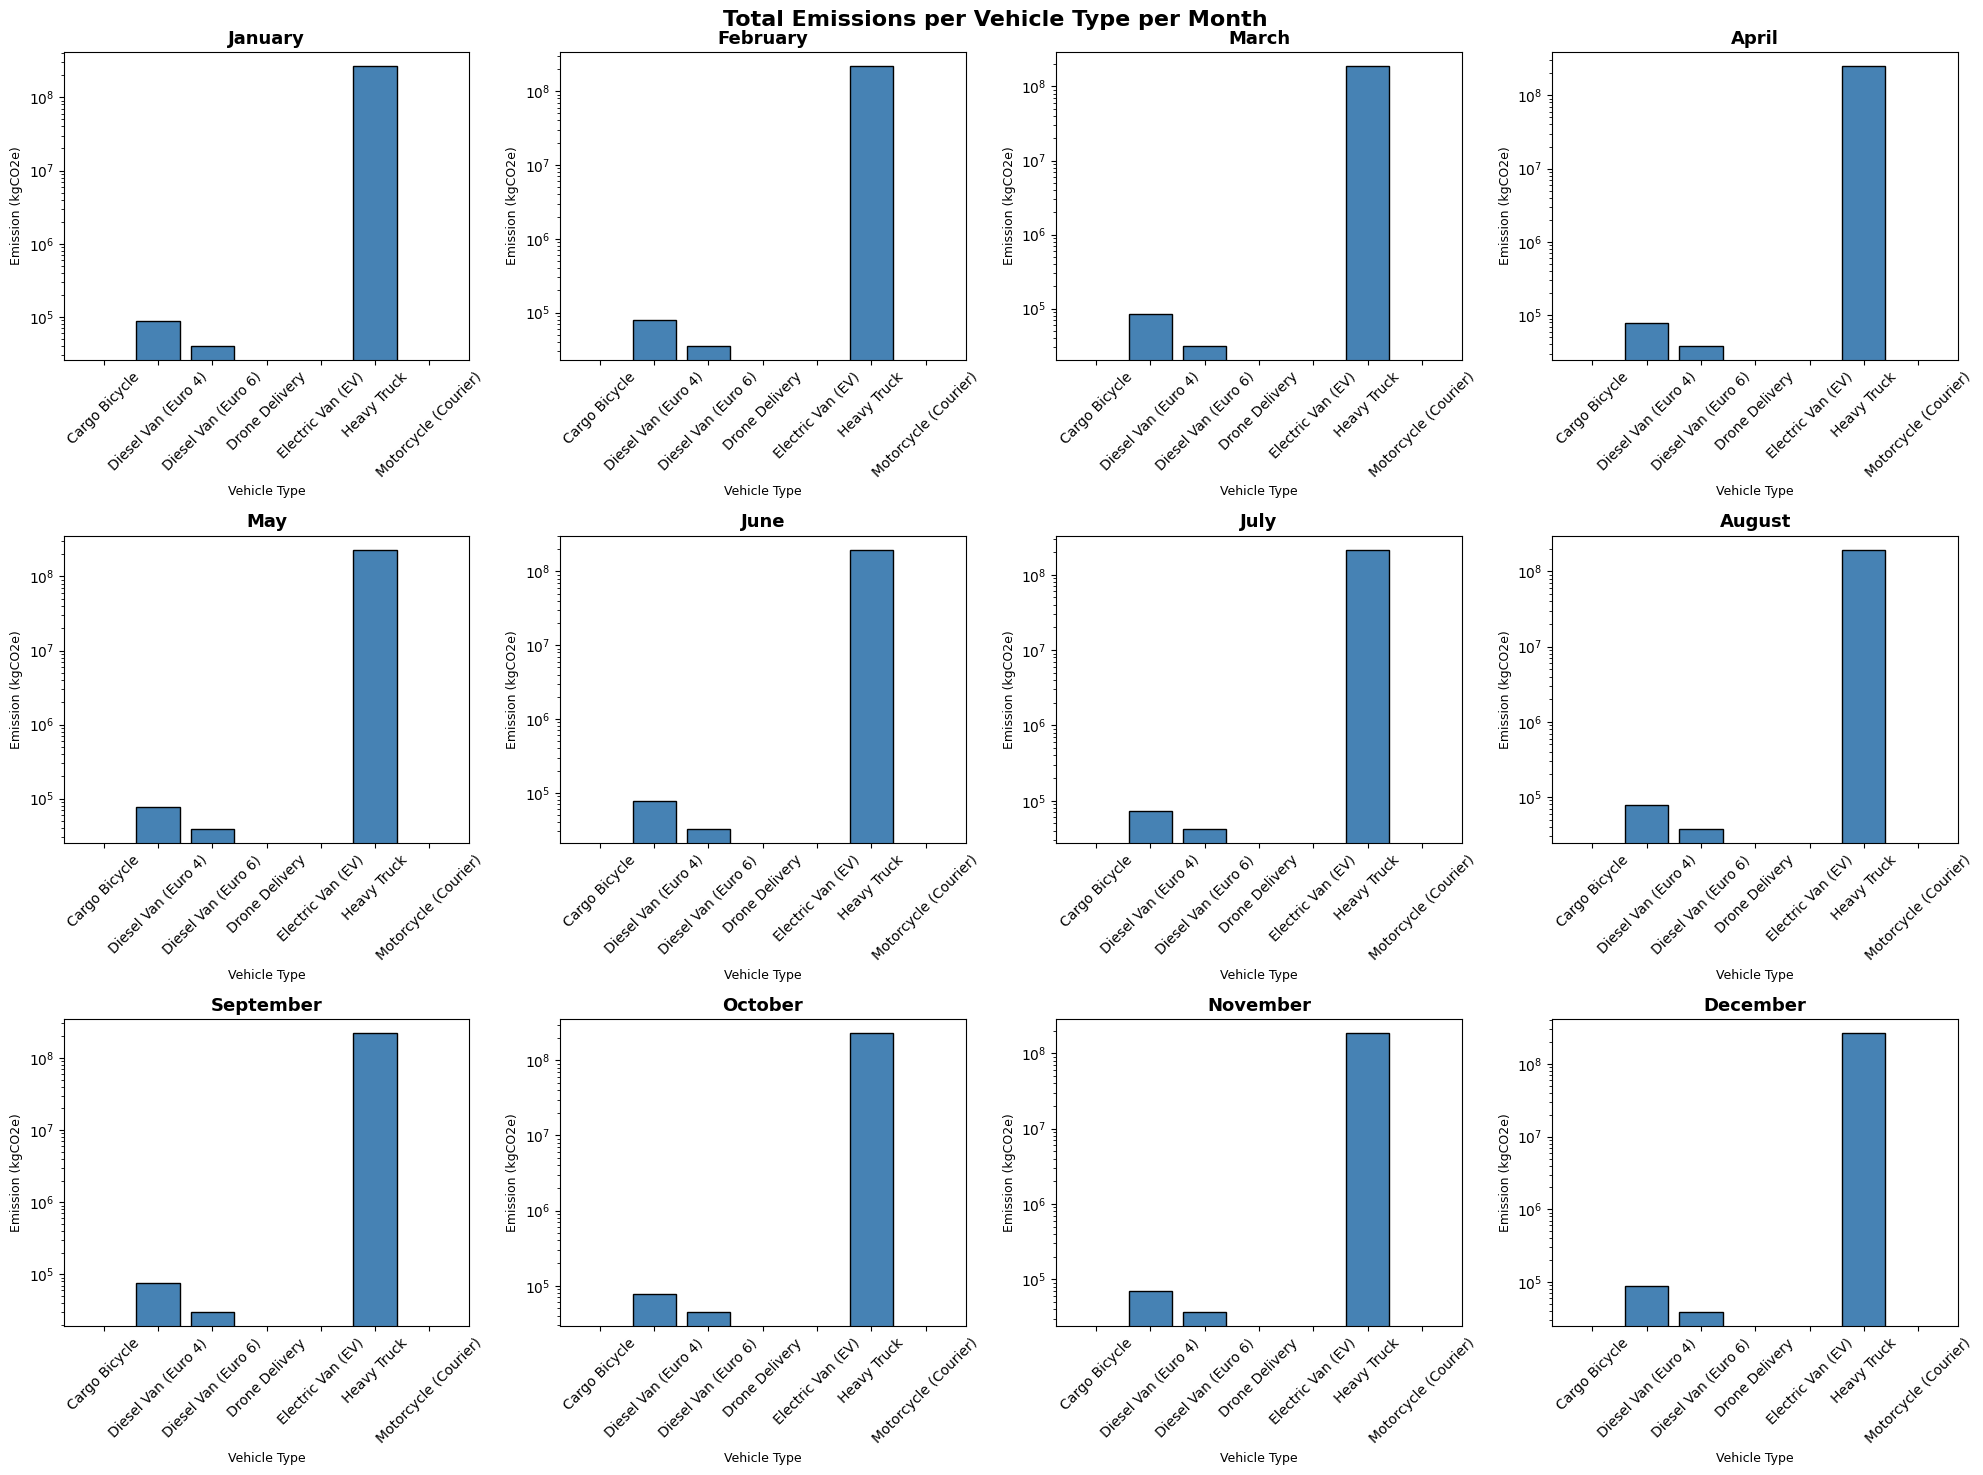

Saved: Visualization_3_emissions_per_month.png


In [16]:
months_ordered = em_per_month.sort_values('Month_Num')['Month'].unique()

n_months = len(months_ordered)
n_cols = 4
n_rows = (n_months + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 5), sharey=False)
axes = axes.flatten()

for i, month in enumerate(months_ordered):
    ax = axes[i]
    data = em_per_month[em_per_month['Month'] == month].sort_values('Vehicle_Type')

    ax.bar(data['Vehicle_Type'], data['Total_Emissions'],
           color='steelblue',
           edgecolor='black')

    # Log scale on y-axis so all vehicle types are visible
    ax.set_yscale('log')

    ax.set_title(month, fontsize=13, fontweight='bold')
    ax.set_ylabel('Emission (kgCO2e)', fontsize=9)
    ax.set_xlabel('Vehicle Type', fontsize=9)
    ax.tick_params(axis='x', rotation=45)

# Hide unused panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Total Emissions per Vehicle Type per Month', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('Visualization_3_emissions_per_month.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: Visualization_3_emissions_per_month.png")